# Copper Price Forecasting and Model Comparison (2010–2026)

**Purpose:** Reproduce paper-inspired descriptive tables and figures, compare models, and use `GridSearchCV` to print each model's best parameters in a style similar to the course homework.

**Models:** Regression Tree (Liu et al., 2017); Random Forest and Gradient Boosting Regression (Díaz et al., 2020); XGBoost (included as an additional model if `xgboost` is installed); Random Walk benchmark.

**Important methodology note:** This is an educational implementation inspired by the papers, not an exact replication. It uses the supplied Investing.com futures/index CSVs, common-date observations from 2010–2026, chronological train/test split, and time-series cross-validation. Forecast horizons are approximate trading-day steps. Hyperparameter tuning is performed on a representative configuration (D=10 lags, one-month horizon) to keep runtime manageable; the selected models are then compared across the requested lag lengths and horizons.


## 1. Imports and configuration

In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scipy.stats import pearsonr

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
BASE = Path.cwd()
OUT = BASE / "copper_forecasting_outputs"
OUT.mkdir(exist_ok=True)

START_DATE, END_DATE = "2010-01-01", "2026-10-13"
FILES = {
    "Copper": "Copper Futures Historical Data.csv",
    "Gold": "Gold Futures Historical Data.csv",
    "Silver": "Silver Futures Historical Data.csv",
    "Oil": "Crude Oil WTI Futures Historical Data.csv",
    "Gas": "Natural Gas Futures Historical Data.csv",
    "Lean Hogs": "Lean Hogs Futures Historical Data.csv",
    "Coffee": "US Coffee C Futures Historical Data.csv",
    "Dow Jones": "Dow Jones Industrial Average Historical Data.csv",
}

try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("xgboost is not installed; the XGBoost model will be skipped.")


## 2. Load, clean, and align the data

In [3]:
frames = []
for variable, filename in FILES.items():
    file_path = BASE / filename
    if not file_path.exists():
        raise FileNotFoundError(
            f"Could not find {filename}. Put all eight CSV files in: {BASE}"
        )
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["Price"] = (df["Price"].astype(str)
                   .str.replace(",", "", regex=False)
                   .str.replace("%", "", regex=False))
    df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
    df = df[["Date", "Price"]].dropna().drop_duplicates("Date")
    df = df.rename(columns={"Price": variable})
    frames.append(df)

data = frames[0]
for frame in frames[1:]:
    data = data.merge(frame, on="Date", how="inner")

data = (data.sort_values("Date").set_index("Date")
        .loc[START_DATE:END_DATE].dropna())
variables = list(FILES.keys())
print(f"Observations after joining all eight series: {len(data):,}")
print(f"Date range: {data.index.min().date()} through {data.index.max().date()}")
display(data.head())


Observations after joining all eight series: 3,684
Date range: 2010-01-13 through 2026-10-13


,Copper,Gold,Silver,Oil,Gas,Lean Hogs,Coffee,Dow Jones
Date,,,,,,,,
2010-01-13,3.4000,1136.8,18.550,79.65,5.733,68.97,145.15,10680.77
2010-01-14,3.3875,1143.0,18.655,79.39,5.588,69.05,144.35,10710.55
2010-01-15,3.3660,1130.5,18.427,78.00,5.691,69.97,140.75,10609.65
2010-01-20,3.3550,1112.6,17.880,77.62,5.496,70.45,139.20,10603.15
2010-01-21,3.2950,1103.2,17.510,76.08,5.615,70.80,138.70,10389.88


## 3. Table 1: descriptive statistics and correlations

Panel A — Descriptive statistics


,Mean,Std. Dev.,Min,Max
Copper,3.537,0.972,1.944,6.888
Gold,1786.358,849.363,1049.600,5354.800
Silver,25.688,13.450,11.772,115.148
Oil,72.768,20.739,11.570,119.780
Gas,3.398,1.174,1.546,9.647
Lean Hogs,81.638,16.153,37.330,133.880
Coffee,179.419,71.016,86.650,432.350
Dow Jones,24772.464,11514.317,9686.480,54349.120


Panel B — Pearson correlations (* p < 0.05)


,Copper,Gold,Silver,Oil,Gas,Lean Hogs,Coffee,Dow Jones
Copper,1.000,0.839*,0.842*,0.473*,0.214*,0.466*,0.773*,0.660*
Gold,0.839*,1.000,0.895*,0.121*,-0.025,0.252*,0.745*,0.807*
Silver,0.842*,0.895*,1.000,0.324*,0.032,0.310*,0.707*,0.528*
Oil,0.473*,0.121*,0.324*,1.000,0.490*,0.651*,0.330*,-0.111*
Gas,0.214*,-0.025,0.032,0.490*,1.000,0.428*,0.264*,-0.041*
Lean Hogs,0.466*,0.252*,0.310*,0.651*,0.428*,1.000,0.433*,0.138*
Coffee,0.773*,0.745*,0.707*,0.330*,0.264*,0.433*,1.000,0.524*
Dow Jones,0.660*,0.807*,0.528*,-0.111*,-0.041*,0.138*,0.524*,1.000


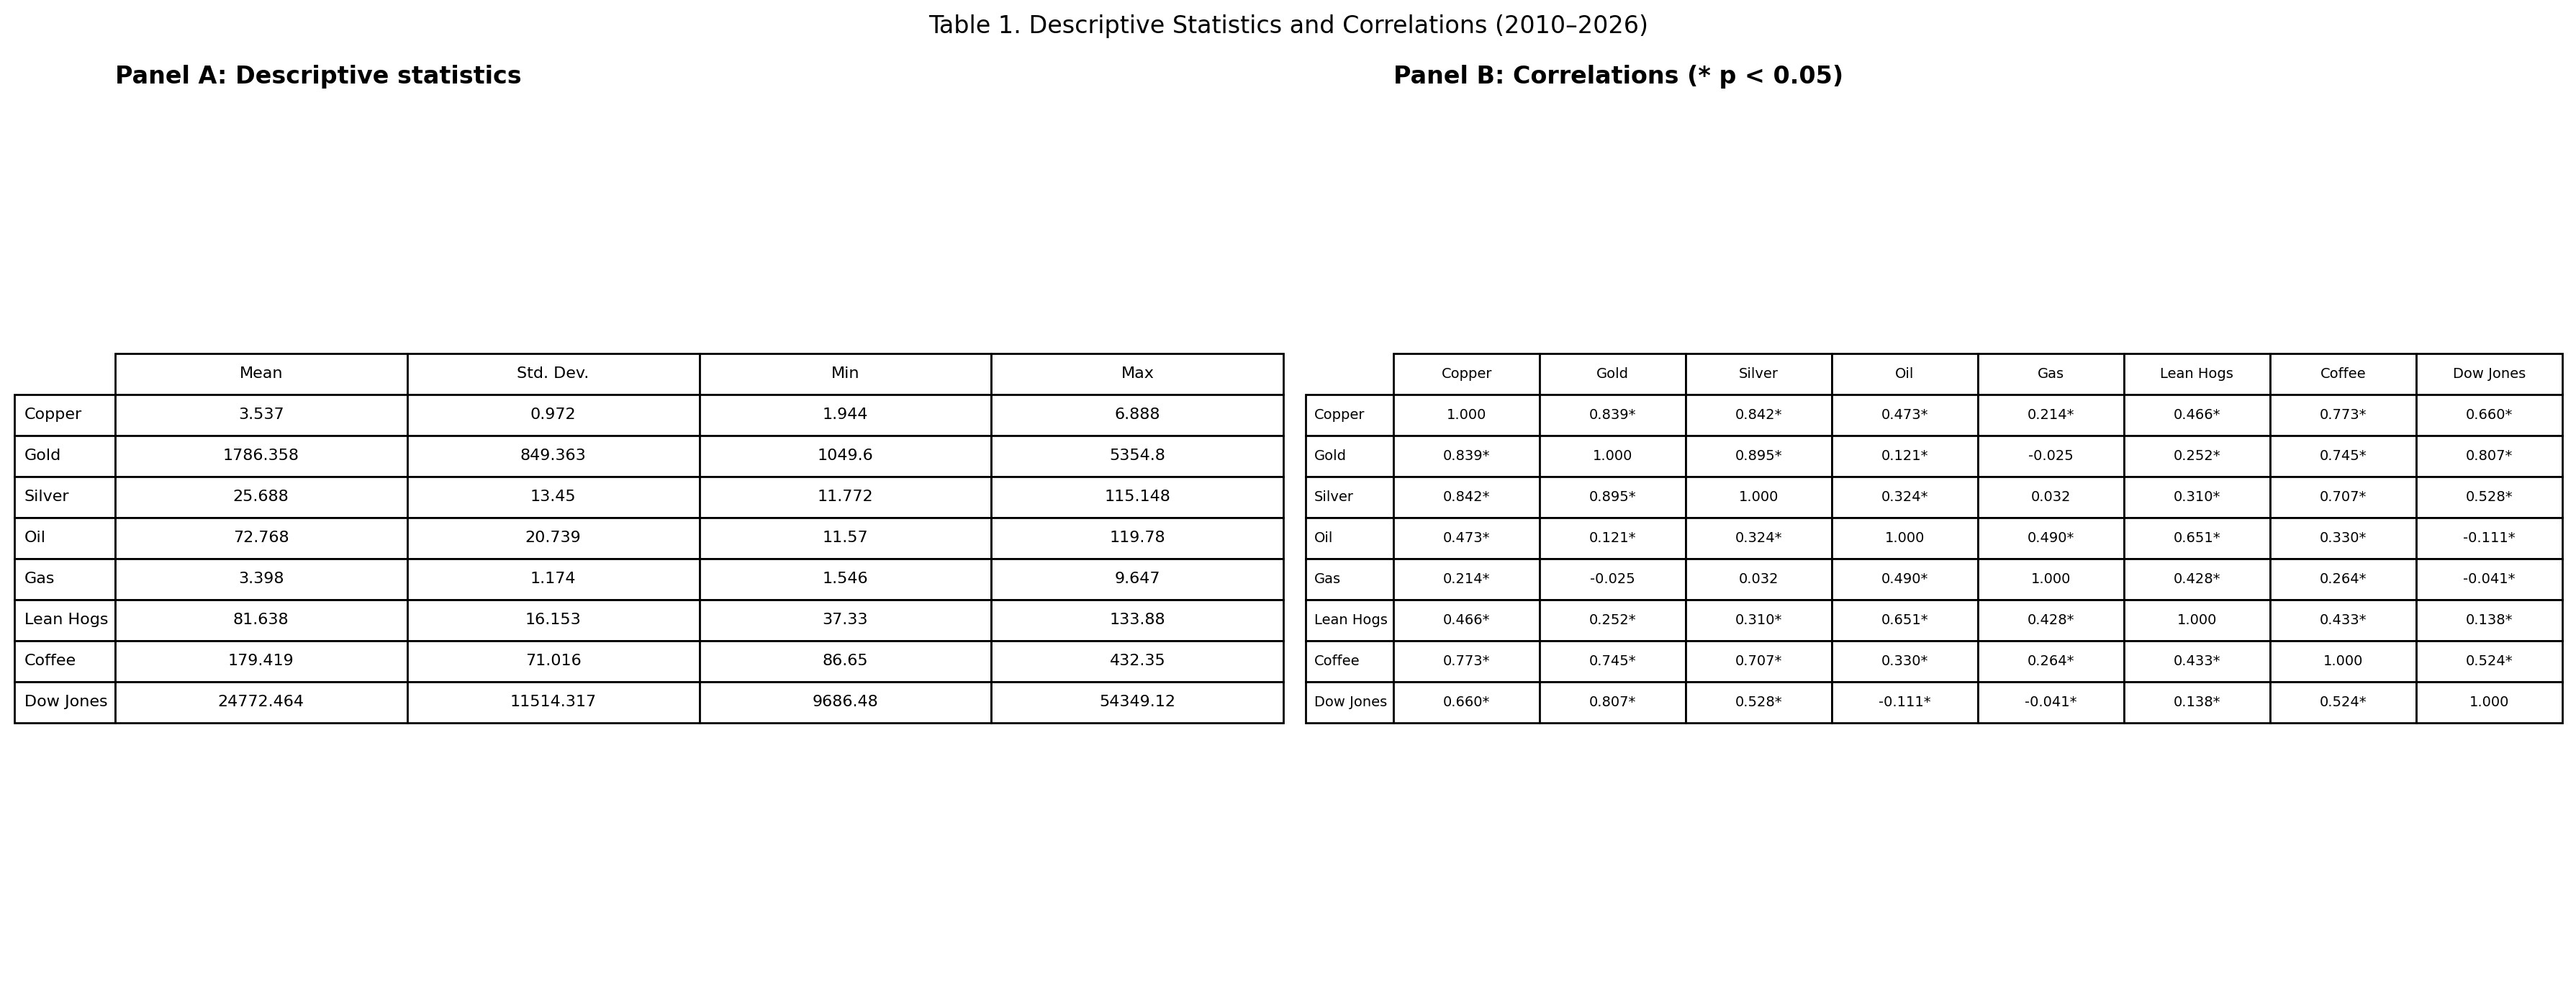

In [4]:
stats = pd.DataFrame({
    "Mean": data.mean(),
    "Std. Dev.": data.std(ddof=1),
    "Min": data.min(),
    "Max": data.max()
}).round(3)

corr = data.corr()
pvals = pd.DataFrame(np.ones_like(corr), index=corr.index, columns=corr.columns)
for i, a in enumerate(variables):
    for j, b in enumerate(variables):
        if i != j:
            _, pvals.loc[a, b] = pearsonr(data[a], data[b])

corr_text = corr.copy().astype(object)
for a in variables:
    for b in variables:
        if a == b:
            corr_text.loc[a, b] = "1.000"
        else:
            star = "*" if pvals.loc[a, b] < 0.05 else ""
            corr_text.loc[a, b] = f"{corr.loc[a,b]:.3f}{star}"

print("Panel A — Descriptive statistics")
display(stats)
print("Panel B — Pearson correlations (* p < 0.05)")
display(corr_text)

stats.to_csv(OUT / "table1_panel_A_descriptive_statistics.csv")
corr_text.to_csv(OUT / "table1_panel_B_correlations.csv")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].axis("off")
t1 = axes[0].table(cellText=np.round(stats.values, 3), rowLabels=stats.index,
                   colLabels=stats.columns, loc="center", cellLoc="center")
t1.auto_set_font_size(False); t1.set_fontsize(8); t1.scale(1, 1.5)
axes[0].set_title("Panel A: Descriptive statistics", loc="left", fontweight="bold")
axes[1].axis("off")
t2 = axes[1].table(cellText=corr_text.values, rowLabels=corr_text.index,
                   colLabels=corr_text.columns, loc="center", cellLoc="center")
t2.auto_set_font_size(False); t2.set_fontsize(7); t2.scale(1, 1.5)
axes[1].set_title("Panel B: Correlations (* p < 0.05)", loc="left", fontweight="bold")
fig.suptitle("Table 1. Descriptive Statistics and Correlations (2010–2026)")
fig.tight_layout()
fig.savefig(OUT / "table1_descriptive_statistics_and_correlations.png", dpi=200, bbox_inches="tight")
display(Image(filename=str(OUT / "table1_descriptive_statistics_and_correlations.png")))
plt.close(fig)


## 4. Figure 1: all eight price series

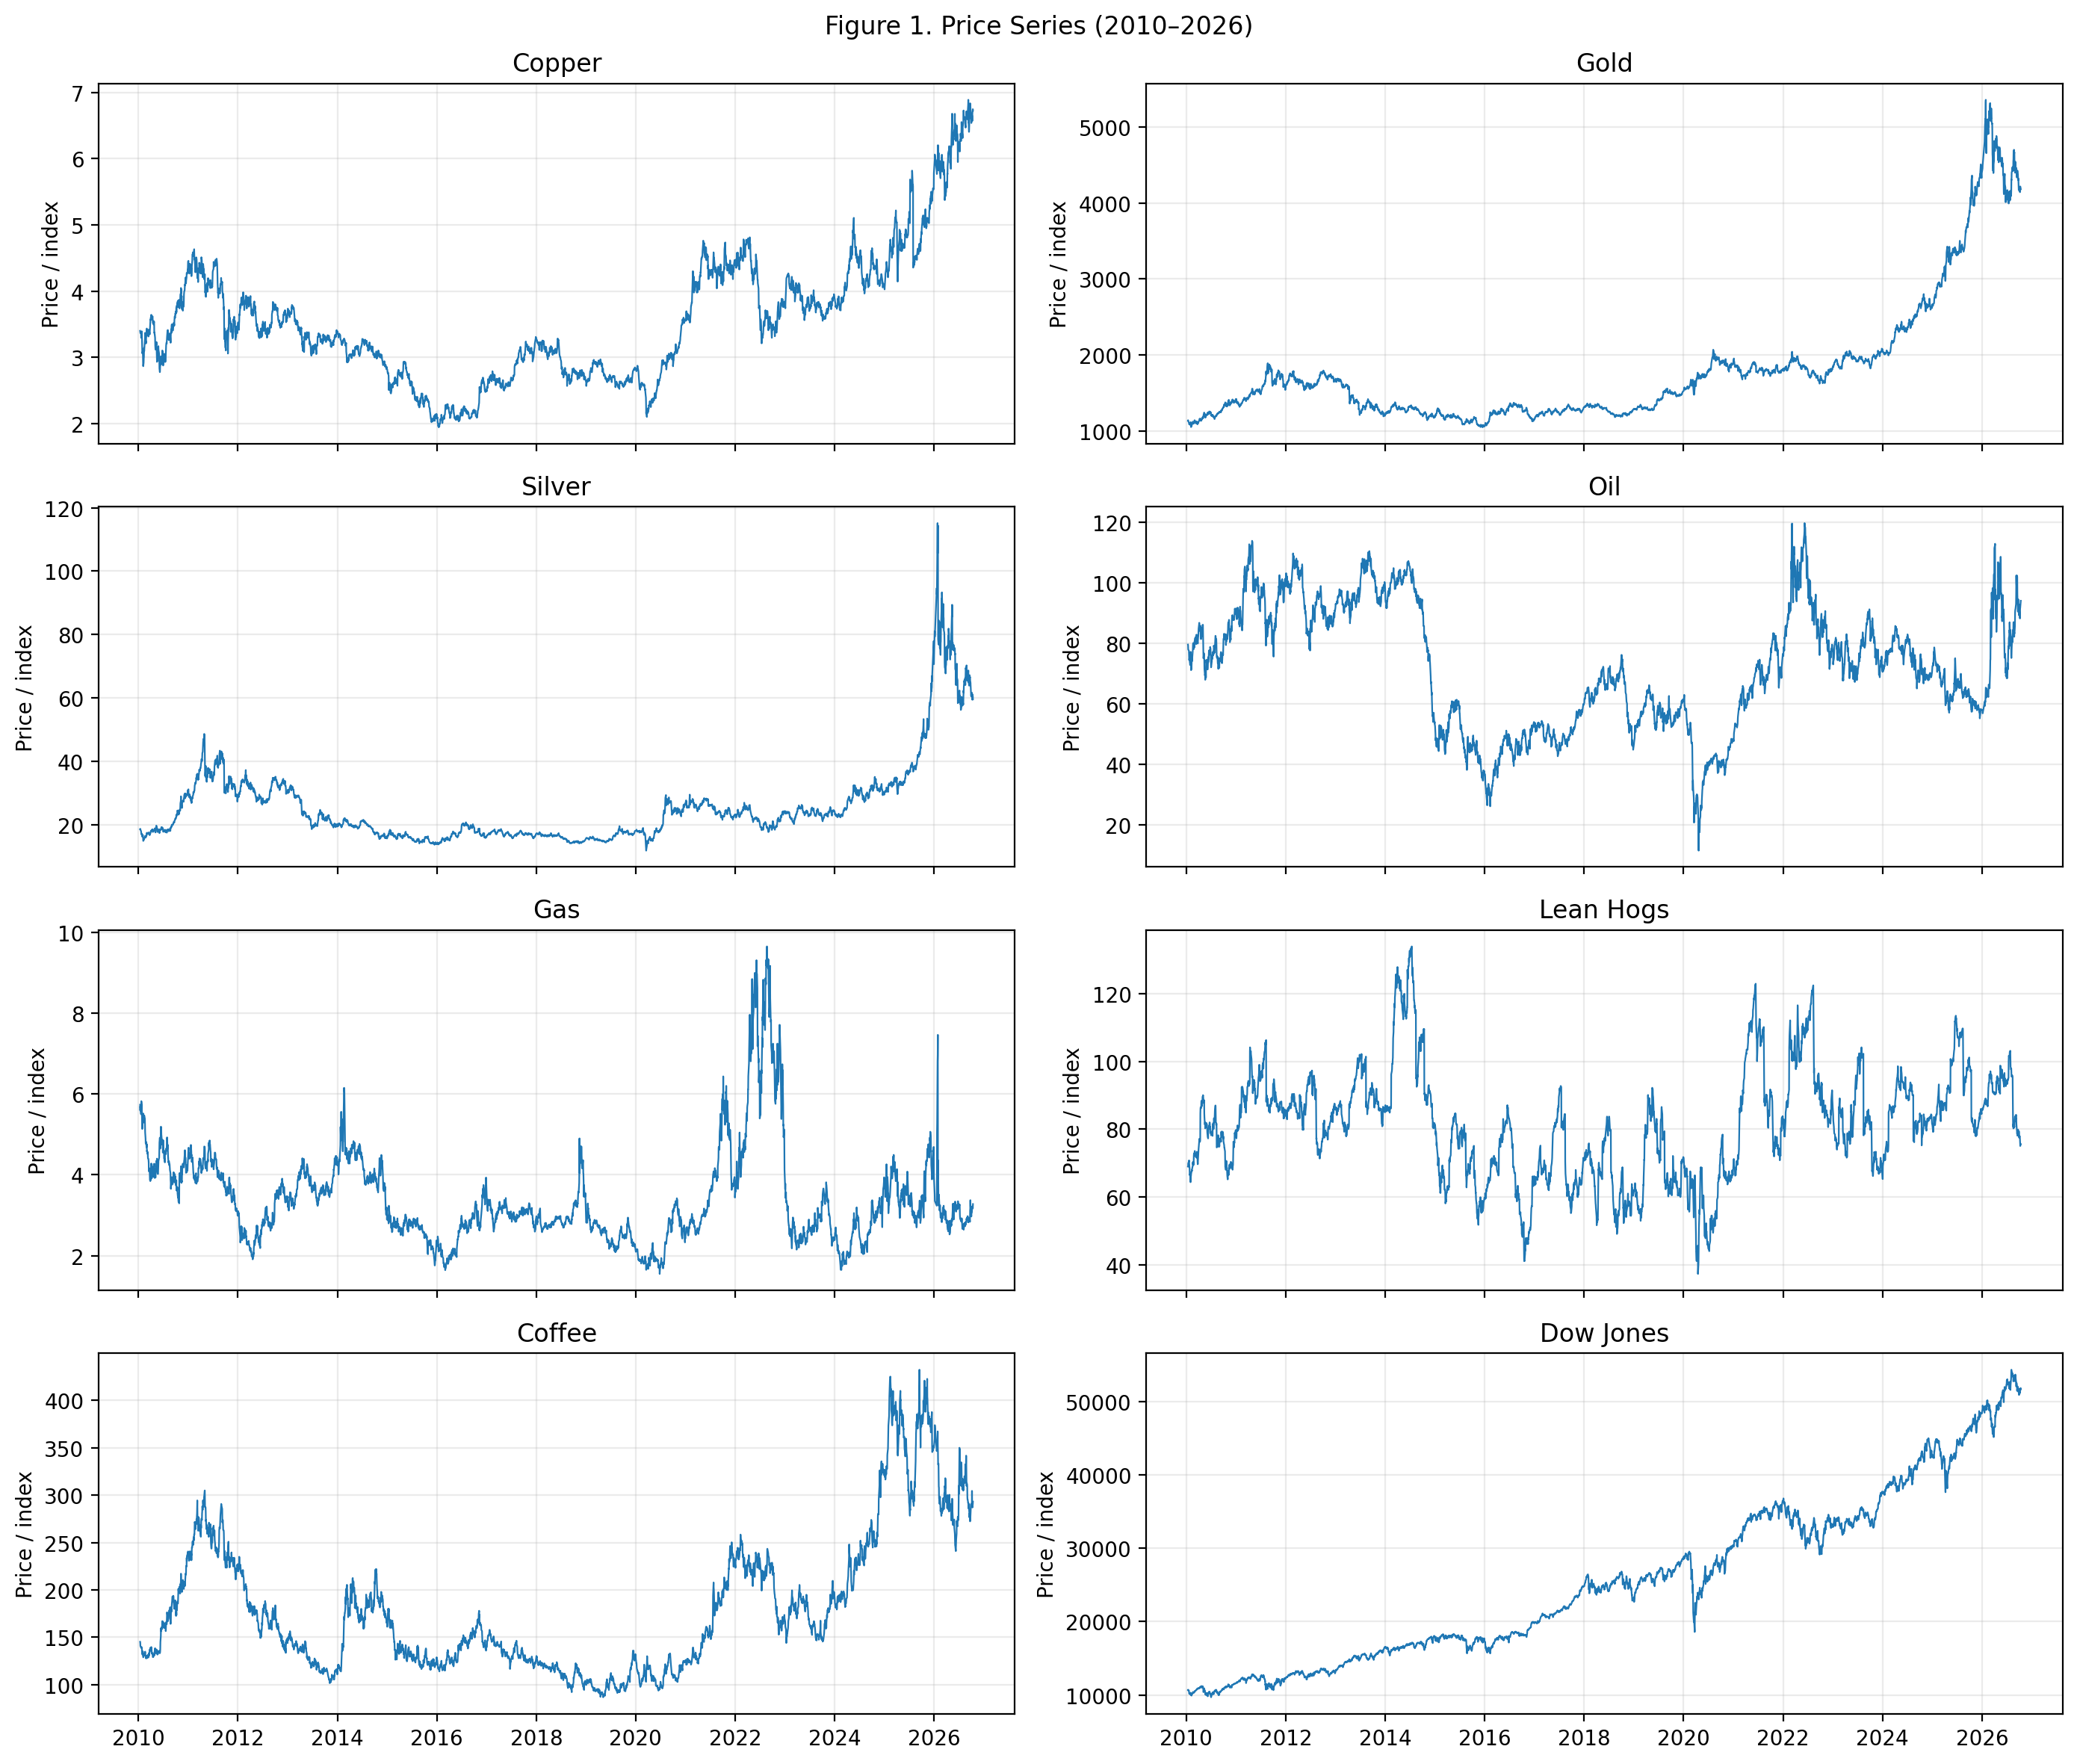

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for ax, col in zip(axes.ravel(), variables):
    ax.plot(data.index, data[col], linewidth=.8)
    ax.set_title(col); ax.set_ylabel("Price / index"); ax.grid(alpha=.25)
fig.suptitle("Figure 1. Price Series (2010–2026)")
fig.tight_layout()
fig.savefig(OUT / "figure1_price_series.png", dpi=200, bbox_inches="tight")
display(Image(filename=str(OUT / "figure1_price_series.png")))
plt.close(fig)


## 5. Figure 2: copper versus explanatory variables

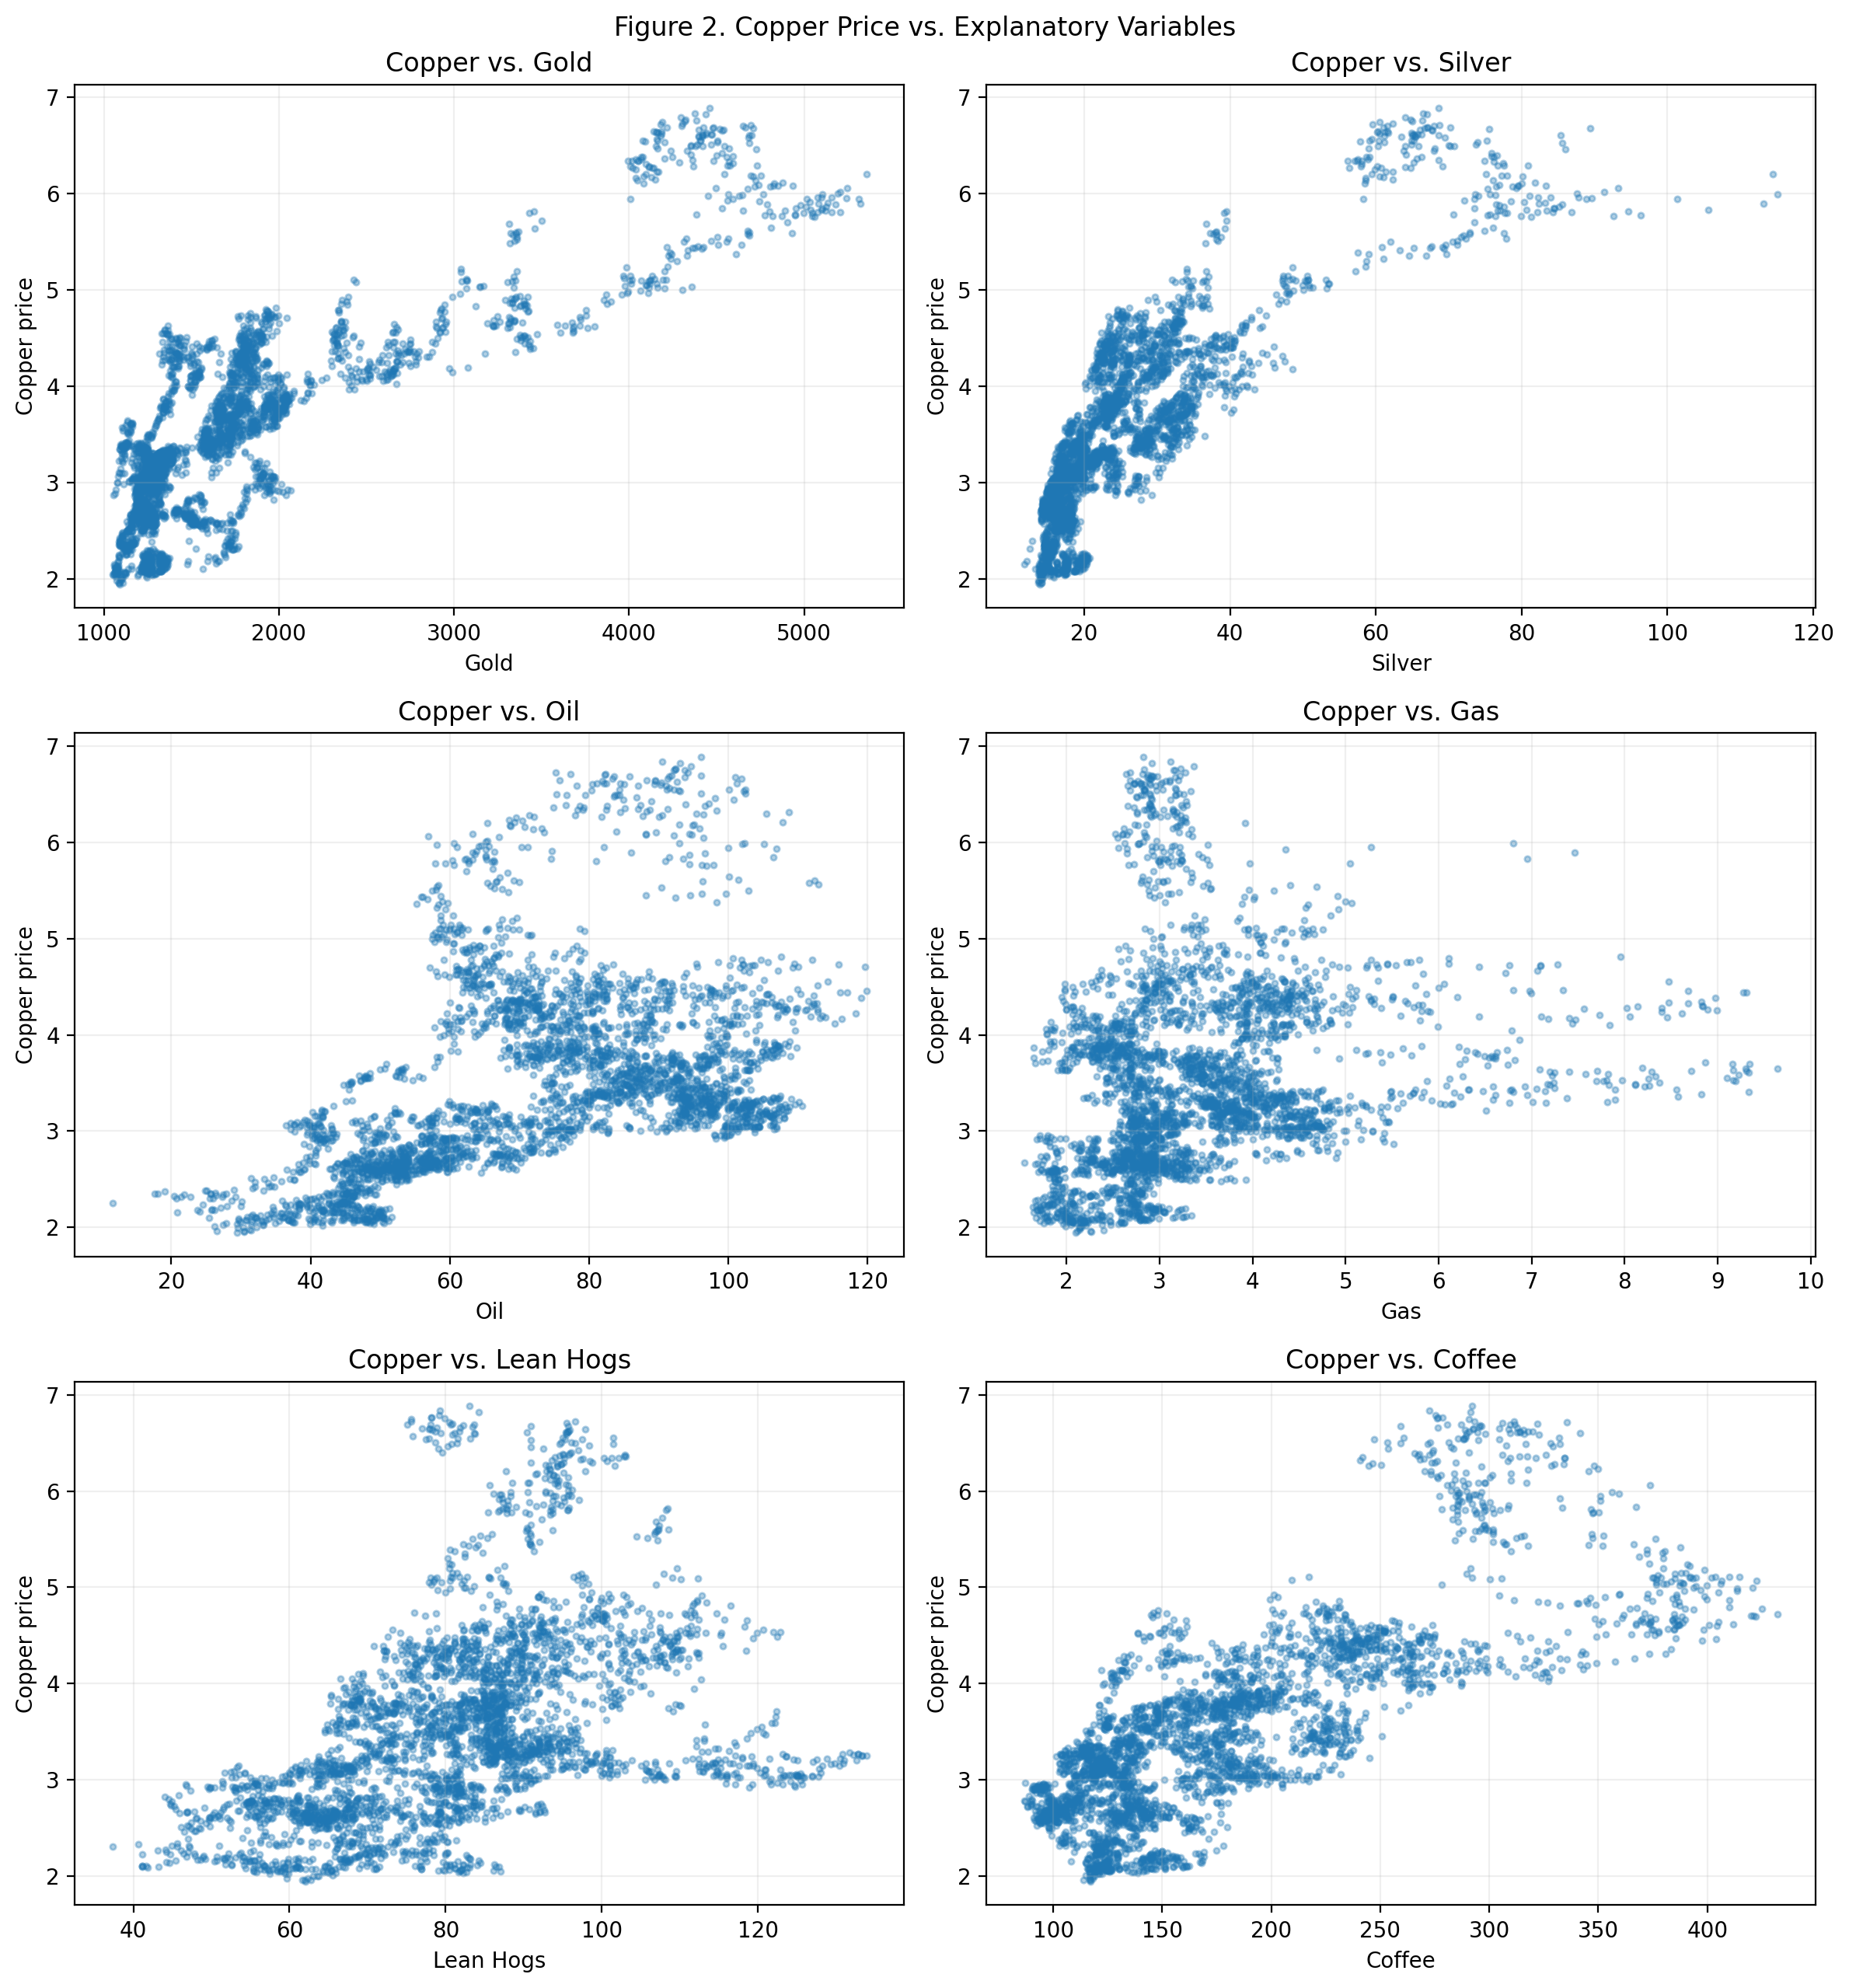

In [6]:
others = [v for v in variables if v != "Copper"]
fig, axes = plt.subplots(3, 2, figsize=(12, 13))
for ax, col in zip(axes.ravel(), others):
    ax.scatter(data[col], data["Copper"], s=7, alpha=.35)
    ax.set_xlabel(col); ax.set_ylabel("Copper price")
    ax.set_title(f"Copper vs. {col}"); ax.grid(alpha=.2)
fig.suptitle("Figure 2. Copper Price vs. Explanatory Variables")
fig.tight_layout()
fig.savefig(OUT / "figure2_copper_scatterplots.png", dpi=200, bbox_inches="tight")
display(Image(filename=str(OUT / "figure2_copper_scatterplots.png")))
plt.close(fig)


## 6. Figure 3: copper price correlations

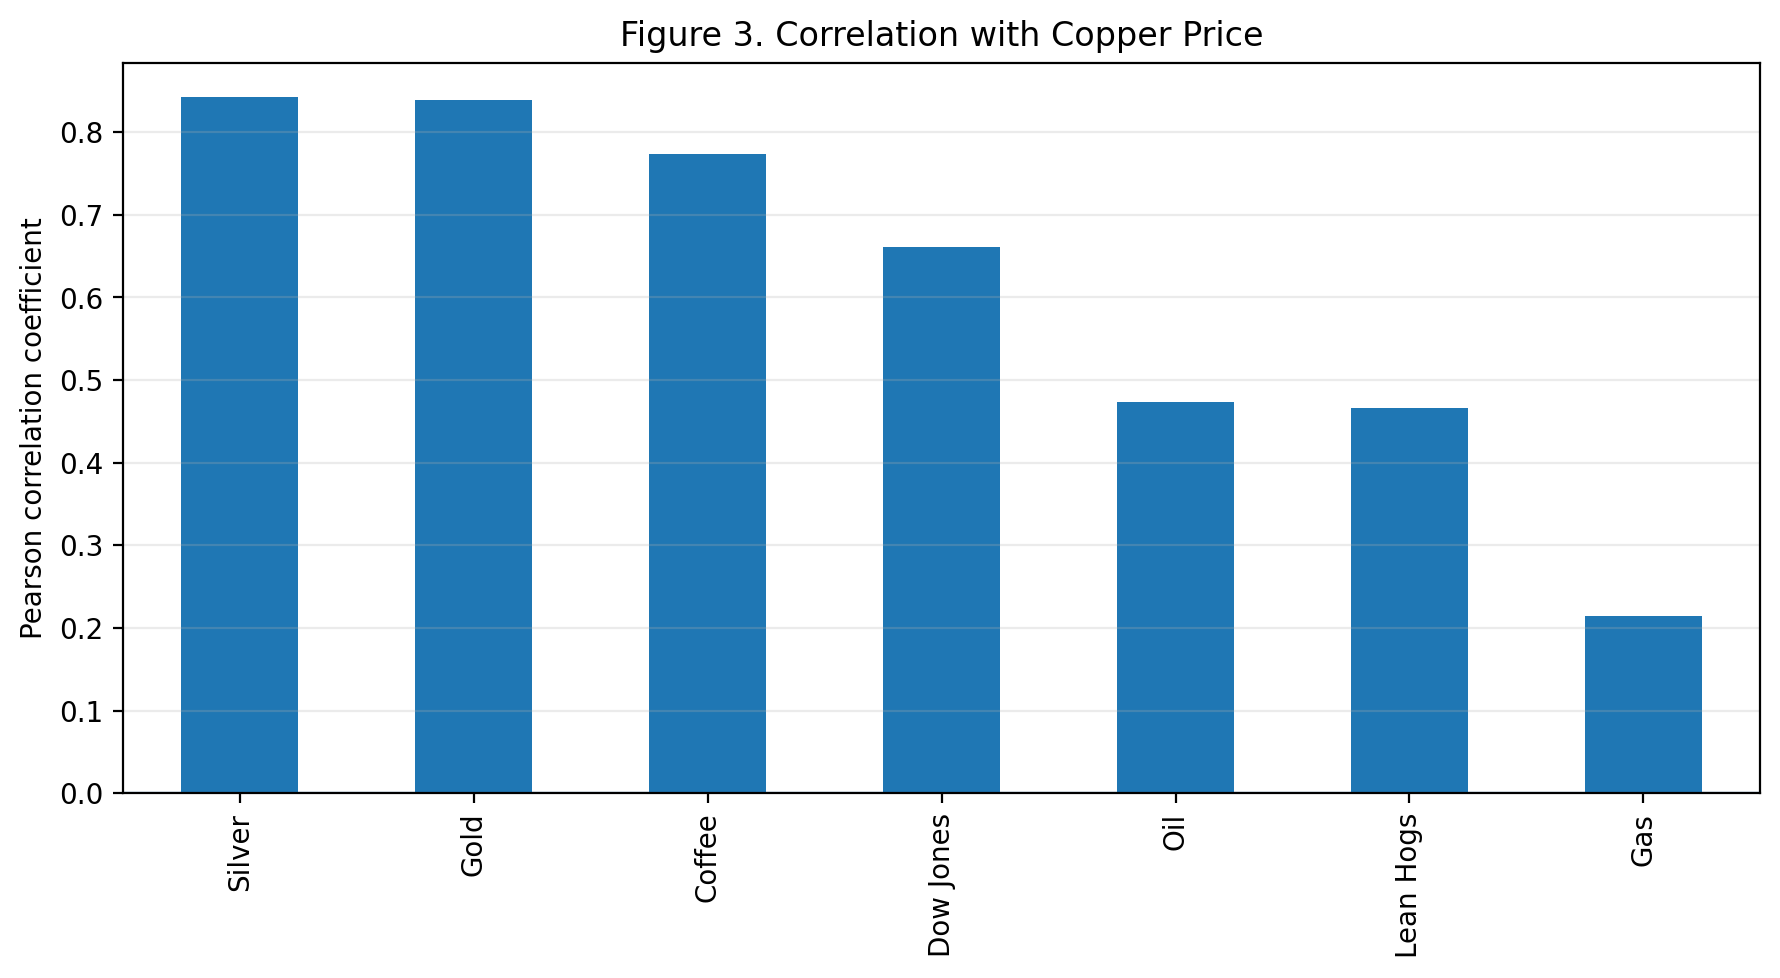

In [7]:
cross = corr.loc[others, "Copper"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
cross.plot(kind="bar", ax=ax)
ax.set_ylabel("Pearson correlation coefficient")
ax.set_title("Figure 3. Correlation with Copper Price")
ax.axhline(0, linewidth=.8); ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "figure3_copper_correlations.png", dpi=200, bbox_inches="tight")
display(Image(filename=str(OUT / "figure3_copper_correlations.png")))
plt.close(fig)


## 7. Build lagged forecasting datasets

For each lag length D, predictors are the previous D observations of all eight series. The target is copper price H trading observations into the future. The final 20% of dates are held out for testing; cross-validation uses `TimeSeriesSplit` on the training data, never random shuffling.

In [8]:
HORIZONS = {
    "1 day": 1, "1 week": 5, "1 month": 21,
    "6 months": 126, "1 year": 252, "2 years": 504
}
LAGS = [1, 5, 10, 20, 40, 80]
TUNE_D = 10
TUNE_H = HORIZONS["1 month"]

def make_supervised(frame, D, horizon):
    X = pd.DataFrame(index=frame.index)
    for col in variables:
        for lag in range(1, D + 1):
            X[f"{col}_lag{lag}"] = frame[col].shift(lag)
    y = frame["Copper"].shift(-horizon).rename("target")
    ds = X.join(y).dropna()
    return ds.drop(columns="target"), ds["target"]

split_idx = int(len(data) * 0.8)
split_date = data.index[split_idx]
print("Chronological training/test split date:", split_date.date())
print("Training observations precede the split; test observations follow it.")

Chronological training/test split date: 2023-03-21
Training observations precede the split; test observations follow it.


## 8. Tune model hyperparameters (homework-style GridSearchCV)

In [9]:
def model_grids():
    grids = {
        "RT": (
            DecisionTreeRegressor(random_state=RANDOM_STATE),
            {
                "max_depth": [4, 8, None],
                "min_samples_leaf": [2, 5, 10],
                "min_samples_split": [2, 10],
            }
        ),
        "RF": (
            RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
            {
                "n_estimators": [100, 200],
                "max_depth": [8, None],
                "min_samples_leaf": [2, 5],
                "max_features": [0.7, 1.0],
            }
        ),
        "GBM": (
            GradientBoostingRegressor(random_state=RANDOM_STATE),
            {
                "n_estimators": [100, 200],
                "max_depth": [1, 2, 3],
                "learning_rate": [0.03, 0.1],
                "min_samples_leaf": [3, 5],
            }
        ),
    }
    if HAS_XGBOOST:
        grids["XGBoost"] = (
            XGBRegressor(random_state=RANDOM_STATE, objective="reg:squarederror",
                         n_jobs=-1, verbosity=0),
            {
                "n_estimators": [100, 200],
                "max_depth": [3, 5],
                "learning_rate": [0.03, 0.1],
                "subsample": [0.8, 1.0],
            }
        )
    return grids

X_tune, y_tune = make_supervised(data, TUNE_D, TUNE_H)
train_mask = X_tune.index < split_date
X_train_tune, y_train_tune = X_tune.loc[train_mask], y_tune.loc[train_mask]
X_test_tune, y_test_tune = X_tune.loc[~train_mask], y_tune.loc[~train_mask]

print(f"Tuning configuration: D={TUNE_D} lags, horizon={TUNE_H} trading days")
print(f"Training rows: {len(X_train_tune):,}; held-out test rows: {len(X_test_tune):,}")

# Expanding-window time-series CV on training data
tscv = TimeSeriesSplit(n_splits=3)
tuned_models = {}
tuning_rows = []

for name, (estimator, param_grid) in model_grids().items():
    print(f"\nTuning {name} ...")
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        n_jobs=-1,
        refit=True,
        verbose=0
    )
    search.fit(X_train_tune, y_train_tune)
    tuned_models[name] = search.best_estimator_
    print("Best parameters:", search.best_params_)
    print(f"Best time-series CV RMSE: {-search.best_score_:.4f}")
    tuning_rows.append({
        "Model": name,
        "Best CV RMSE": -search.best_score_,
        "Best Parameters": str(search.best_params_)
    })

tuning_table = pd.DataFrame(tuning_rows).sort_values("Best CV RMSE")
print("\nHyperparameter tuning summary")
display(tuning_table)
tuning_table.to_csv(OUT / "table_model_tuning_best_parameters.csv", index=False)


Tuning configuration: D=10 lags, horizon=21 trading days
Training rows: 2,937; held-out test rows: 716

Tuning RT ...
Best parameters: {'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best time-series CV RMSE: 0.4549

Tuning RF ...
Best parameters: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 5, 'n_estimators': 200}
Best time-series CV RMSE: 0.4716

Tuning GBM ...
Best parameters: {'learning_rate': 0.03, 'max_depth': 1, 'min_samples_leaf': 3, 'n_estimators': 200}
Best time-series CV RMSE: 0.4863

Tuning XGBoost ...
Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best time-series CV RMSE: 0.4756

Hyperparameter tuning summary


,Model,Best CV RMSE,Best Parameters
0,RT,0.454854,"{'max_depth': 4, 'min_samples_leaf': 10, 'min_..."
1,RF,0.471557,"{'max_depth': None, 'max_features': 1.0, 'min_..."
3,XGBoost,0.475645,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."
2,GBM,0.486292,"{'learning_rate': 0.03, 'max_depth': 1, 'min_s..."


## 9. Compare tuned models on the held-out set

Held-out model comparison (D=10, one-month horizon)


,Model,MAE,RMSE,R2,MAPE (%)
4,RW,0.2830,0.3670,0.8533,5.8267
2,GBM,0.7724,1.1110,-0.3443,13.6881
3,XGBoost,0.8498,1.2456,-0.6898,15.0111
0,RT,0.9041,1.3055,-0.8562,16.0747
1,RF,0.9865,1.4557,-1.3081,17.4076


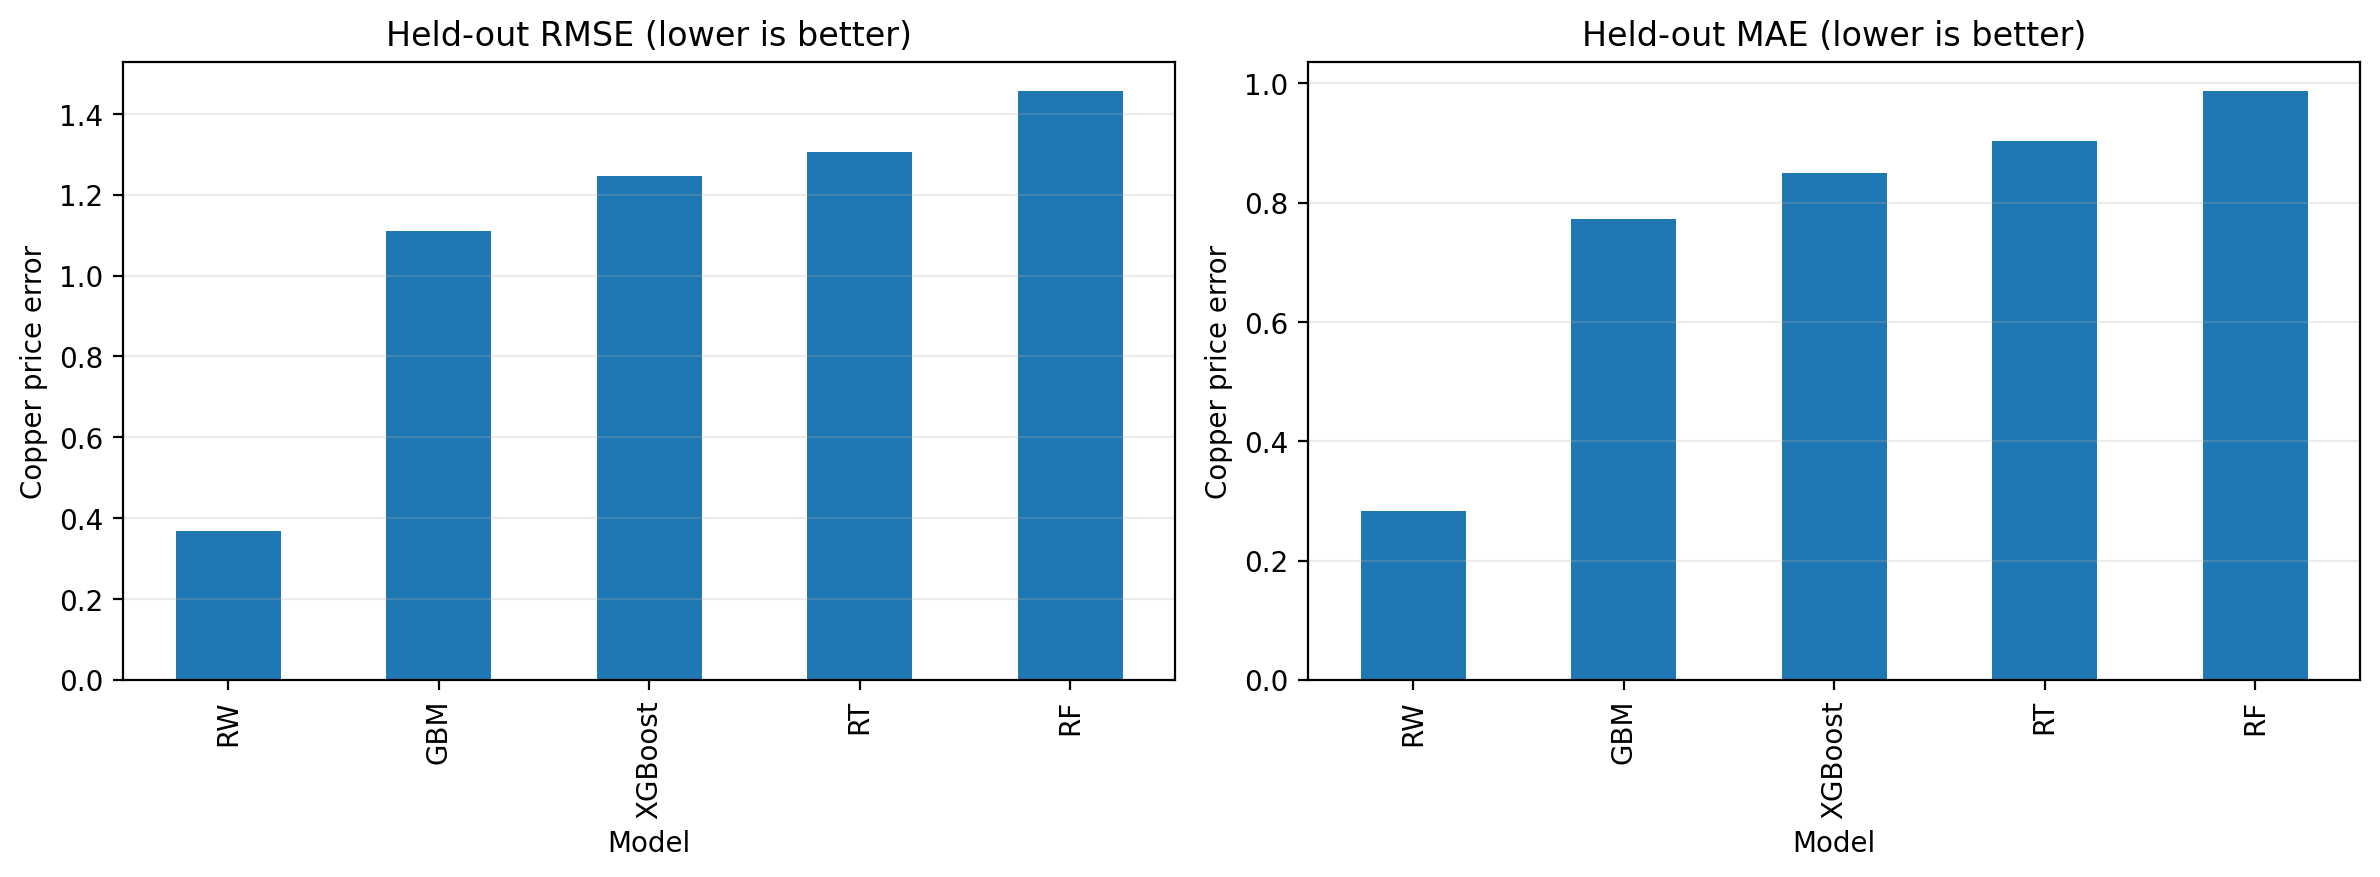

In [11]:
comparison_rows = []
predictions = {}
for name, model in tuned_models.items():
    model.fit(X_train_tune, y_train_tune)
    pred = model.predict(X_test_tune)
    predictions[name] = pred
    comparison_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_tune, pred),
        "RMSE": mean_squared_error(y_test_tune, pred) ** 0.5,
        "R2": r2_score(y_test_tune, pred),
        "MAPE (%)": np.mean(np.abs((y_test_tune.to_numpy() - pred) /
                                    np.maximum(np.abs(y_test_tune.to_numpy()), 1e-8))) * 100
    })

# Random walk: use the last observed copper price as forecast
rw_pred = X_test_tune["Copper_lag1"].to_numpy()
predictions["RW"] = rw_pred
comparison_rows.append({
    "Model": "RW",
    "MAE": mean_absolute_error(y_test_tune, rw_pred),
    "RMSE": mean_squared_error(y_test_tune, rw_pred) ** 0.5,
    "R2": r2_score(y_test_tune, rw_pred),
    "MAPE (%)": np.mean(np.abs((y_test_tune.to_numpy() - rw_pred) /
                                np.maximum(np.abs(y_test_tune.to_numpy()), 1e-8))) * 100
})

model_comparison = pd.DataFrame(comparison_rows).sort_values("RMSE")
print("Held-out model comparison (D=10, one-month horizon)")
display(model_comparison.round(4))
model_comparison.to_csv(OUT / "table_model_comparison_test_metrics.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
model_comparison.set_index("Model")["RMSE"].plot(kind="bar", ax=axes[0], title="Held-out RMSE (lower is better)")
model_comparison.set_index("Model")["MAE"].plot(kind="bar", ax=axes[1], title="Held-out MAE (lower is better)")
for ax in axes:
    ax.set_ylabel("Copper price error"); ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "figure4_model_comparison_metrics.png", dpi=200, bbox_inches="tight")
display(Image(filename=str(OUT / "figure4_model_comparison_metrics.png")))
plt.close(fig)


## 10. Forecast tables by lag length and horizon

In [12]:
# Evaluate each tuned estimator across all D/horizon combinations.
# Grid search is not repeated for every configuration; best parameters above are reused.
forecast_rows = []
for D in LAGS:
    for horizon_name, horizon in HORIZONS.items():
        X_all, y_all = make_supervised(data, D, horizon)
        train_mask = X_all.index < split_date
        Xtr, ytr = X_all.loc[train_mask], y_all.loc[train_mask]
        Xte, yte = X_all.loc[~train_mask], y_all.loc[~train_mask]
        if len(Xtr) < 100 or len(Xte) < 20:
            continue
        for name, base_model in tuned_models.items():
            model = base_model
            model.fit(Xtr, ytr)
            pred = model.predict(Xte)
            forecast_rows.append({
                "Model": name, "D": D, "Horizon": horizon_name,
                "Horizon steps": horizon,
                "MAE": mean_absolute_error(yte, pred),
                "RMSE": mean_squared_error(yte, pred) ** 0.5,
                "MAPE (%)": np.mean(np.abs((yte.to_numpy() - pred) /
                                            np.maximum(np.abs(yte.to_numpy()), 1e-8))) * 100
            })
        # RW benchmark uses the latest observed copper value (lag 1)
        rw = Xte["Copper_lag1"].to_numpy()
        forecast_rows.append({
            "Model": "RW", "D": D, "Horizon": horizon_name,
            "Horizon steps": horizon,
            "MAE": mean_absolute_error(yte, rw),
            "RMSE": mean_squared_error(yte, rw) ** 0.5,
            "MAPE (%)": np.mean(np.abs((yte.to_numpy() - rw) /
                                        np.maximum(np.abs(yte.to_numpy()), 1e-8))) * 100
        })

forecast_results = pd.DataFrame(forecast_rows)
print("Forecast evaluation results")
display(forecast_results.head(20).round(4))
forecast_results.to_csv(OUT / "table_forecast_metrics_all_models_lags_horizons.csv", index=False)

best_by_setting = forecast_results.loc[
    forecast_results.groupby(["D", "Horizon"])["RMSE"].idxmin()
].sort_values(["D", "Horizon steps"])
print("Best model for each lag length and forecast horizon (lowest held-out RMSE)")
display(best_by_setting[["D", "Horizon", "Model", "MAE", "RMSE", "MAPE (%)"]].round(4))
best_by_setting.to_csv(OUT / "table_best_model_by_lag_and_horizon.csv", index=False)


Forecast evaluation results


,Model,D,Horizon,Horizon steps,MAE,RMSE,MAPE (%)
0,RT,1,1 day,1,0.5411,0.8772,9.2350
1,RF,1,1 day,1,0.5118,0.8367,8.7315
2,GBM,1,1 day,1,0.6080,0.9597,10.4232
3,XGBoost,1,1 day,1,0.5865,0.9301,10.0728
4,RW,1,1 day,1,0.0884,0.1350,1.8172
5,RT,1,1 week,5,0.5909,0.9103,10.2853
6,RF,1,1 week,5,0.5807,0.8816,10.2546
7,GBM,1,1 week,5,0.6540,0.9955,11.3676
8,XGBoost,1,1 week,5,0.6500,0.9954,11.3814
9,RW,1,1 week,5,0.1597,0.2315,3.3143


Best model for each lag length and forecast horizon (lowest held-out RMSE)


,D,Horizon,Model,MAE,RMSE,MAPE (%)
4,1,1 day,RW,0.0884,0.1350,1.8172
9,1,1 week,RW,0.1597,0.2315,3.3143
14,1,1 month,RW,0.2830,0.3670,5.8267
19,1,6 months,RW,0.6175,0.7507,11.6275
24,1,1 year,RW,1.0386,1.1863,18.6902
26,1,2 years,RF,1.1663,1.3602,18.8948
34,5,1 day,RW,0.0884,0.1350,1.8172
39,5,1 week,RW,0.1597,0.2315,3.3143
44,5,1 month,RW,0.2830,0.3670,5.8267
49,5,6 months,RW,0.6175,0.7507,11.6275


## 11. Figure 5: RMSE by model and forecast horizon

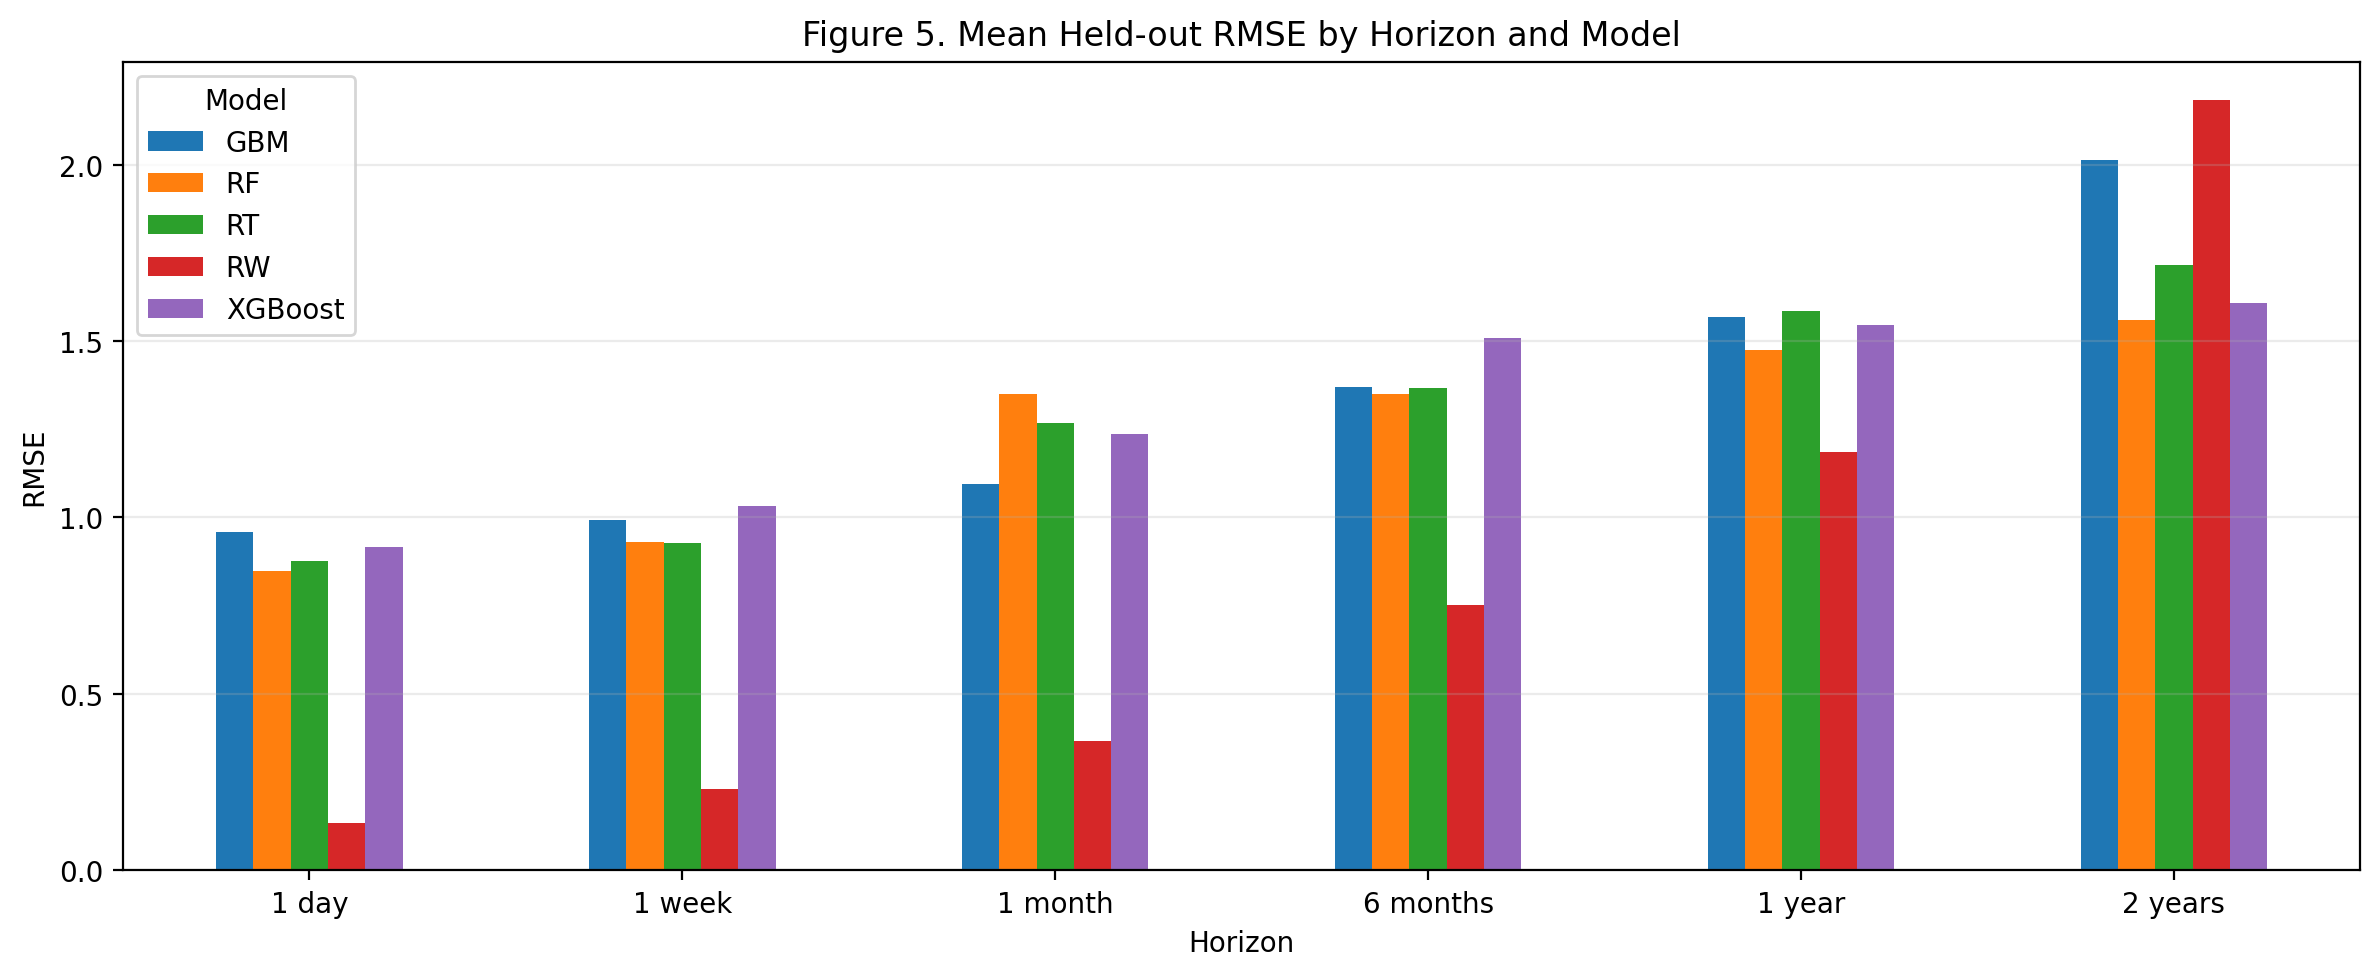

In [13]:
if not forecast_results.empty:
    pivot = forecast_results.groupby(["Horizon", "Model"])["RMSE"].mean().unstack()
    pivot = pivot.reindex(list(HORIZONS.keys()))
    ax = pivot.plot(kind="bar", figsize=(12, 5))
    ax.set_ylabel("RMSE"); ax.set_title("Figure 5. Mean Held-out RMSE by Horizon and Model")
    ax.grid(axis="y", alpha=.25); plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(OUT / "figure5_rmse_by_horizon_model.png", dpi=200, bbox_inches="tight")
    display(Image(filename=str(OUT / "figure5_rmse_by_horizon_model.png")))
    plt.close()


## 12. Figure 6: actual vs. forecast for tuned models

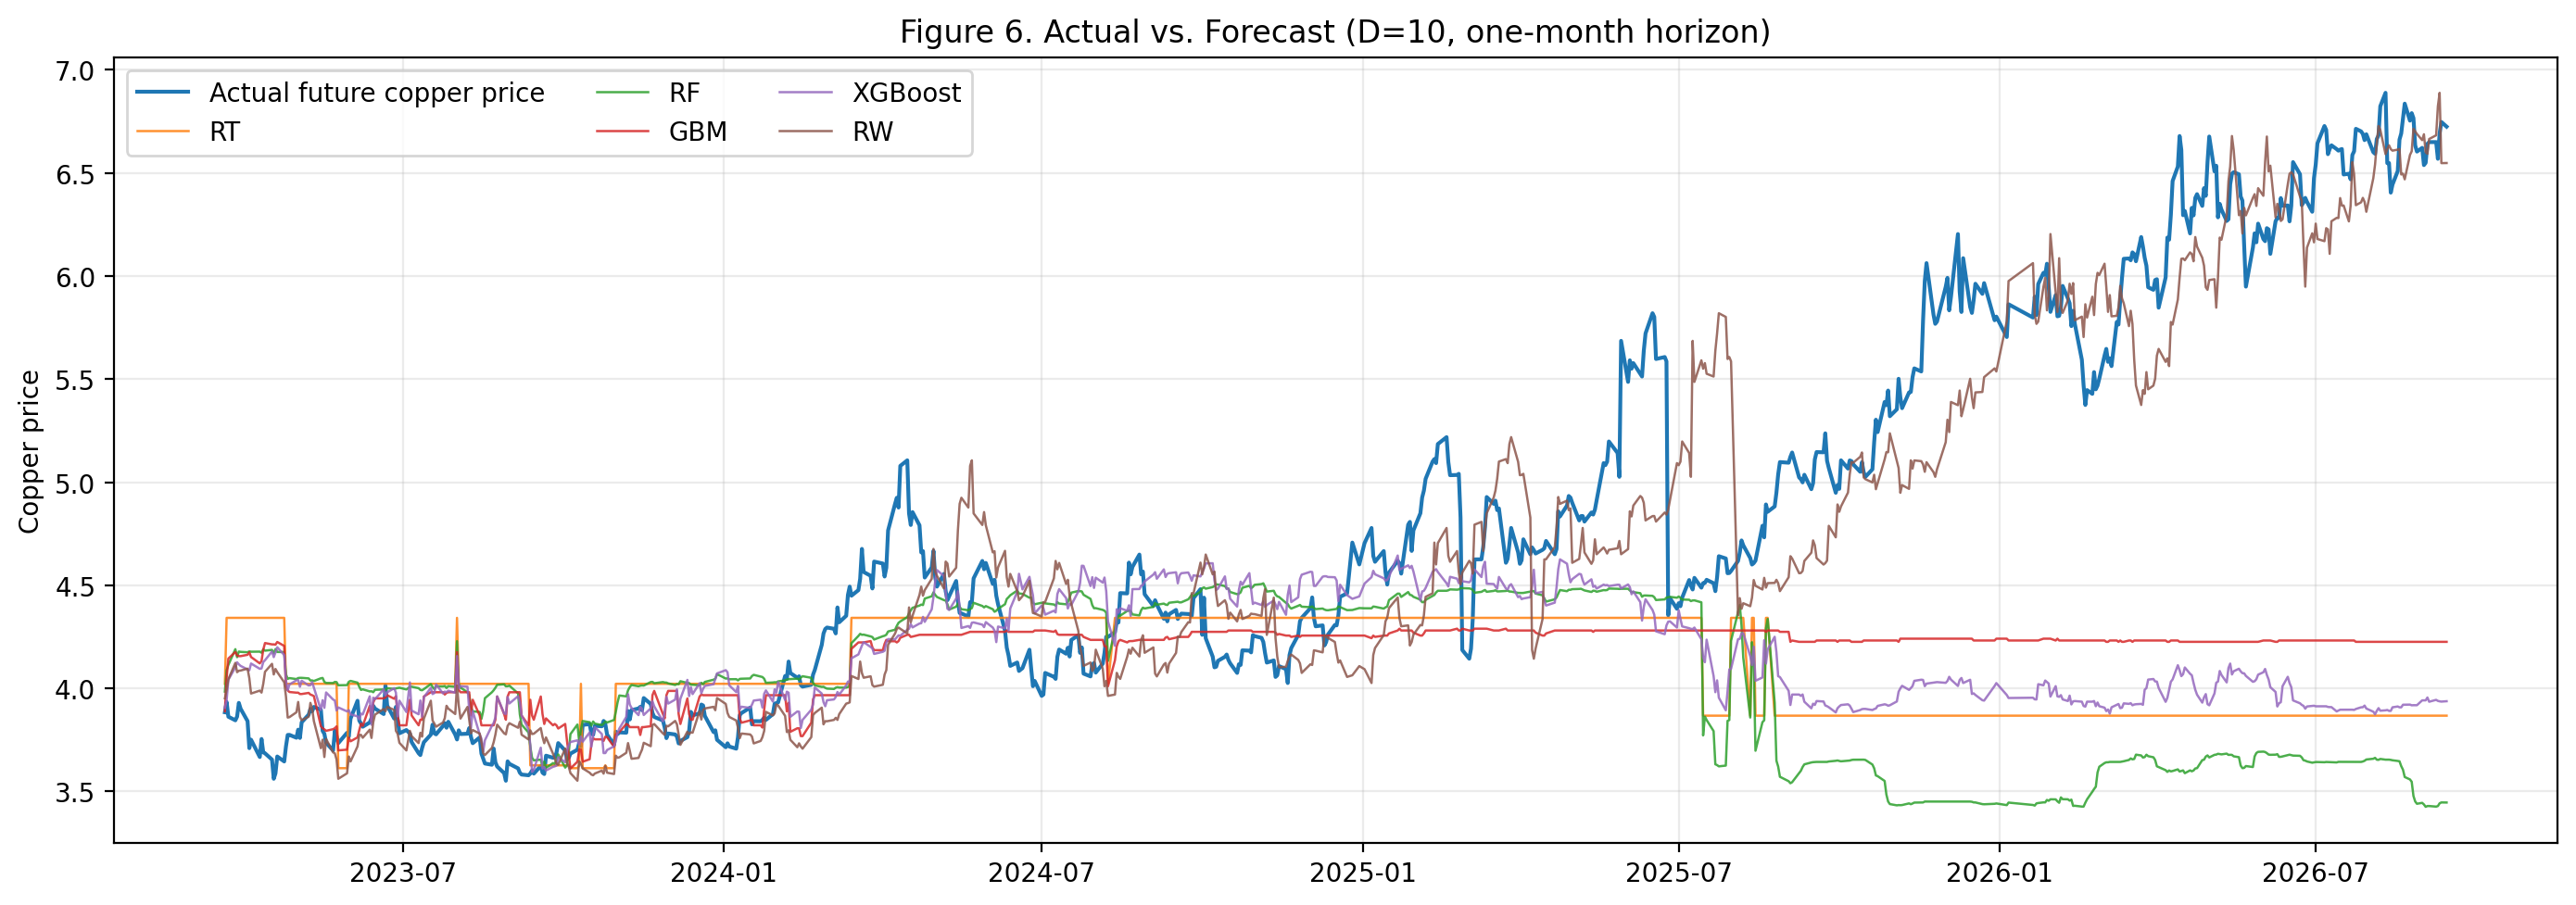

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test_tune.index, y_test_tune.values, label="Actual future copper price", linewidth=1.5)
for name, pred in predictions.items():
    ax.plot(y_test_tune.index, pred, label=name, linewidth=.9, alpha=.85)
ax.set_title("Figure 6. Actual vs. Forecast (D=10, one-month horizon)")
ax.set_ylabel("Copper price"); ax.legend(ncol=3); ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "figure6_actual_vs_forecasts.png", dpi=200, bbox_inches="tight")
display(Image(filename=str(OUT / "figure6_actual_vs_forecasts.png")))
plt.close(fig)


## 13. Feature importance (tree-based models)

In [15]:
for name, model in tuned_models.items():
    if hasattr(model, "feature_importances_"):
        imp = pd.Series(model.feature_importances_, index=X_train_tune.columns).sort_values(ascending=False).head(20)
        print(f"Top 20 feature importances — {name}")
        display(imp.to_frame("Importance"))
        imp.to_csv(OUT / f"feature_importance_{name}.csv")
        fig, ax = plt.subplots(figsize=(9, 6))
        imp.sort_values().plot(kind="barh", ax=ax)
        ax.set_title(f"Figure 7. Top Feature Importances — {name}")
        ax.set_xlabel("Importance"); ax.grid(axis="x", alpha=.25)
        fig.tight_layout()
        fig.savefig(OUT / f"figure7_feature_importance_{name}.png", dpi=200, bbox_inches="tight")
        display(Image(filename=str(OUT / f"figure7_feature_importance_{name}.png")))
        plt.close(fig)


ValueError: Length of values (640) does not match length of index (80)

In [ ]:

print("Number of tuning features:", X_train_tune.shape[1])

for name, model in tuned_models.items():
    if hasattr(model, "feature_importances_"):
        print(
            name,
            type(model).__name__,
            np.asarray(model.feature_importances_).shape
        )


## 14. Output files and interpretation notes

All generated tables and figures are saved in `copper_forecasting_outputs/` as CSV/PNG files as well as displayed inline in the notebook.

- Grid search uses time-series cross-validation and tunes on training data only.
- Test metrics are calculated on the final chronological 20% of observations.
- RMSE/MAE are in the units of the supplied copper futures price series; MAPE is percentage error.
- The random-walk forecast uses the most recent copper price.
- XGBoost is only included if the `xgboost` Python package is installed.
- The paper's original sample starts in 2008 and ends in May 2020; this notebook uses the user's data through 2026, so its results should not be presented as exact replication of the paper.
